# What each systematic uncertainty does

Four views of the systematic uncertainties of the signal, from the outputs of
`03_limits.ipynb` and the same campaign:

1. **Up and down templates.** For one signal point per final state and every entry of
   `systematics.yaml`: the signal $m_{LJLJ}$ distribution in regions A to D with its up and
   down variations, and their ratio to the nominal. They show whether a systematic changes
   only the normalisation, so that one log-normal number per region (what the cards use) is
   enough, or also the shape; whether it is symmetric; and whether the variation stands out
   from the statistical fluctuations of the simulated signal.
2. **Size across the signal grid.** The size in region A of every systematic that varies
   from point to point, and of the statistical uncertainty of the simulated signal, as maps
   over the bound state mass, the dark photon mass and $L_{xy}$.
3. **Impacts.** For the same two points, the shift of the fitted $r$ when each nuisance
   moves by one standard deviation, on the Asimov dataset with the signal injected at the
   point's expected limit (`sidm/scripts/run_combine_impacts.py`). Without an injected
   signal, a nuisance that acts on the signal alone has no impact at all.
4. **Limit breakdown.** The expected limits of the limit grid with each systematic left out
   in turn, all of them left out, and every constrained nuisance fixed (statistics only),
   as the change each makes to the limit with every systematic.

**Rerun after `03_limits.ipynb`** whenever an entry is added to `systematics.yaml`. This
notebook follows the registry and reads the cards, shapes, systematics and limits that
03_limits wrote to EOS; it stops if those are not from the current `systematics.yaml`.

**Simulation only**, as 03_limits. The figures and fit outputs go to EOS, under `effects/`
in the output directory of 03_limits. Combine works in a temporary directory, which is
removed at the end.

**Interpretations.** Each section ends with an interpretation of its results and of what they
mean for the analysis, written for the run named in it. Revise them when a rerun changes the
picture, for example after adding a systematic.

In [1]:
import json, os, shutil, sys, tempfile, warnings
from pathlib import Path
import fsspec
import numpy as np
from IPython.display import Image, display

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # sidm/studies/limit_plotting, put on the path by systematics_study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
dt = sysstudy.dt

CAMPAIGN = "systematics_v1"
dt.use_campaign(CAMPAIGN)
INPUT_DIR = sysstudy.eos_url(dt.CAMPAIGN.bkg_dir)   # the merged outputs of the campaign
LIMITS_DIR = f"{INPUT_DIR}_limits"                  # the outputs of 03_limits.ipynb
OUTPUT_DIR = f"{LIMITS_DIR}/effects"
REGISTRY = sysstudy.load_registry()
KAPPAS = sysstudy.limits_outputs(LIMITS_DIR, REGISTRY)["kappas"]   # stops if 03_limits needs a rerun
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(KAPPAS)
EXPECTED = {r["signal"]: r["exp"] for r in pt.as_rows(f"{LIMITS_DIR}/limits_with/limits.csv")}
POINTS = {"SR_2mu2e": "2Mu2E_500GeV_1p2GeV_1p9mm", "SR_4mu": "4Mu_500GeV_1p2GeV_1p9mm"}   # sections 1 and 3
COMBINE = sysstudy.find_combine()
WORK = Path(tempfile.mkdtemp(prefix=f"effects_{CAMPAIGN}_"))   # removed at the end
FIGURES = WORK / "figures"


def show(path):
    """Display a figure that plot_tools saved"""
    display(Image(filename=str(path.with_suffix(".png"))))


print("inputs: ", INPUT_DIR, "and", LIMITS_DIR)
print("outputs:", OUTPUT_DIR)
print("Combine:", "on the PATH" if COMBINE and COMBINE.no_cmsenv else COMBINE.combine_cmssw if COMBINE else "not found")
print("systematics:", ", ".join(REGISTRY), f"| {len(LIMIT)} points on the limit grid")
print("points:", ", ".join(f"{p} (expected limit {EXPECTED[p]:.3g} fb)" for p in POINTS.values()))

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1 and root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1_limits
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1_limits/effects
Combine: /uscms_data/d3/scampbel/CMSSW_14_1_0_pre4
systematics: lumi_13TeV, CMS_pileup, CMS_l1_prefiring, CMS_jet_energy | 96 points on the limit grid
points: 2Mu2E_500GeV_1p2GeV_1p9mm (expected limit 1.56 fb), 4Mu_500GeV_1p2GeV_1p9mm (expected limit 0.152 fb)


## 1. Up and down templates

A `flat` entry scales the template, a `syst` entry is the Up and Down weight categories of
the campaign, and a `variant` (the jet energy) has an up variation only, which the cards
use symmetrically. The grey band in the ratio panels is the statistical uncertainty of the
nominal template. A variation re-weights or re-sorts the same simulated events, so it is
known better than this band, which shows the size of the fluctuations: a variation that
follows them from bin to bin is noise rather than a shape.

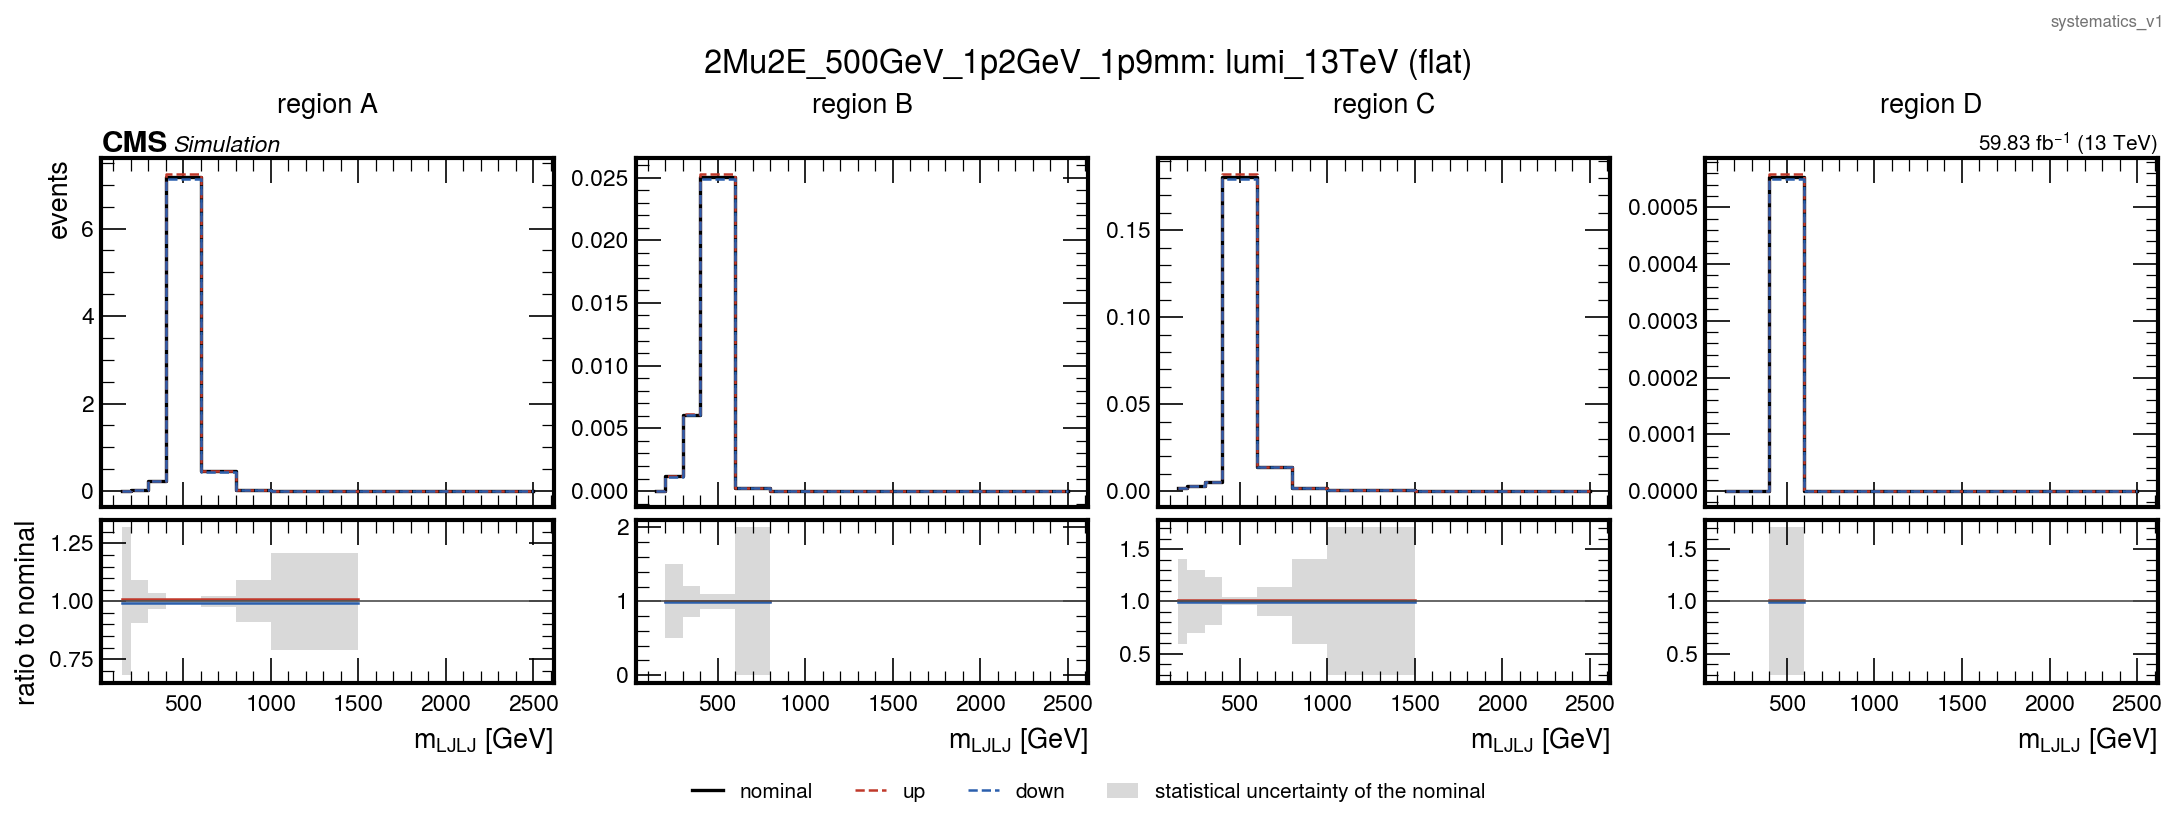

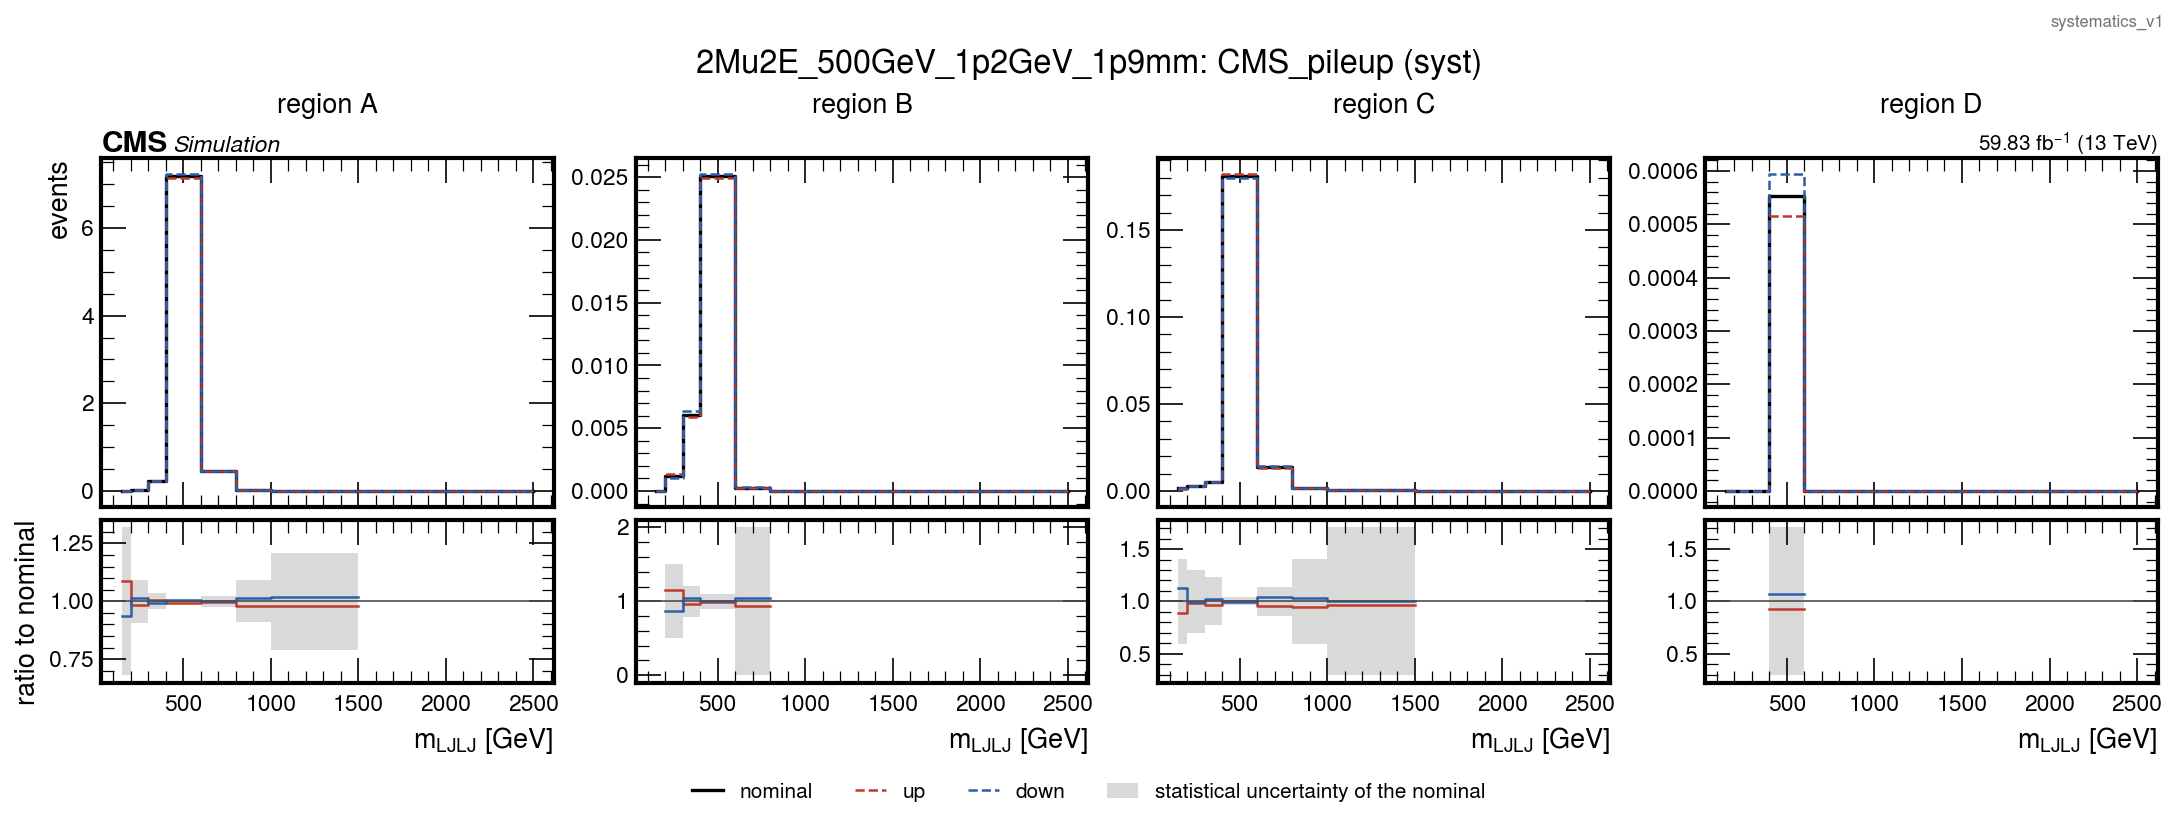

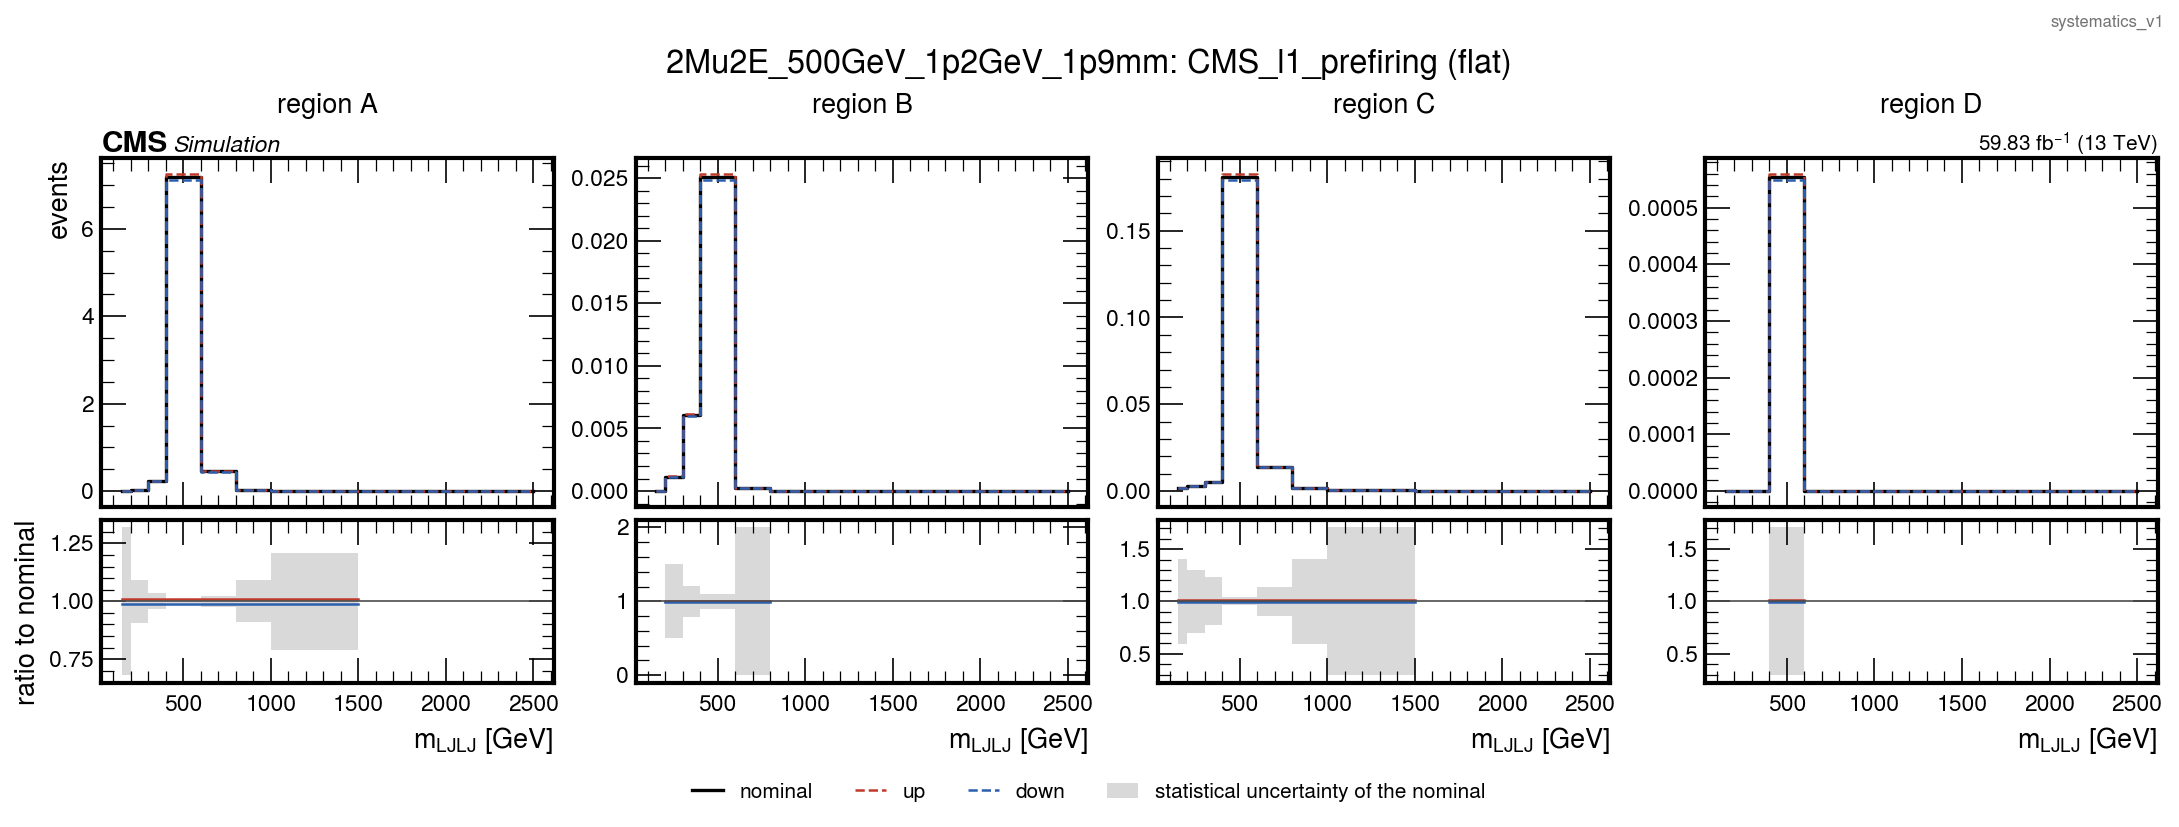

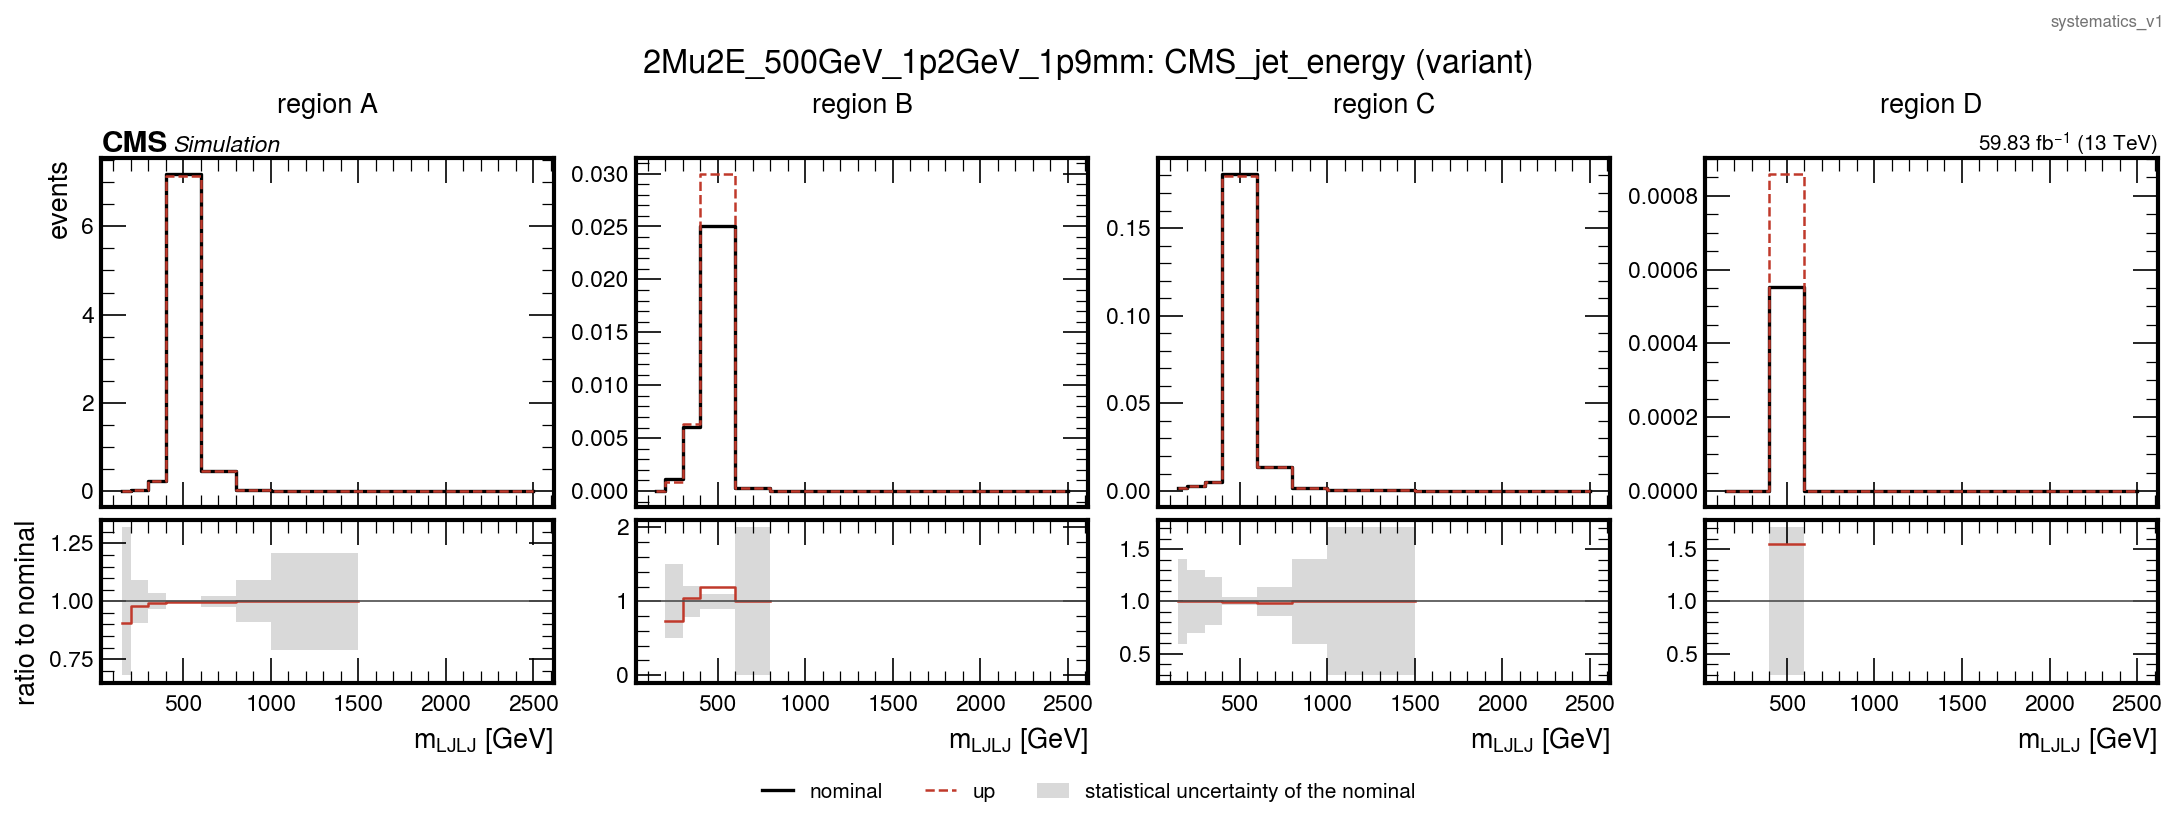

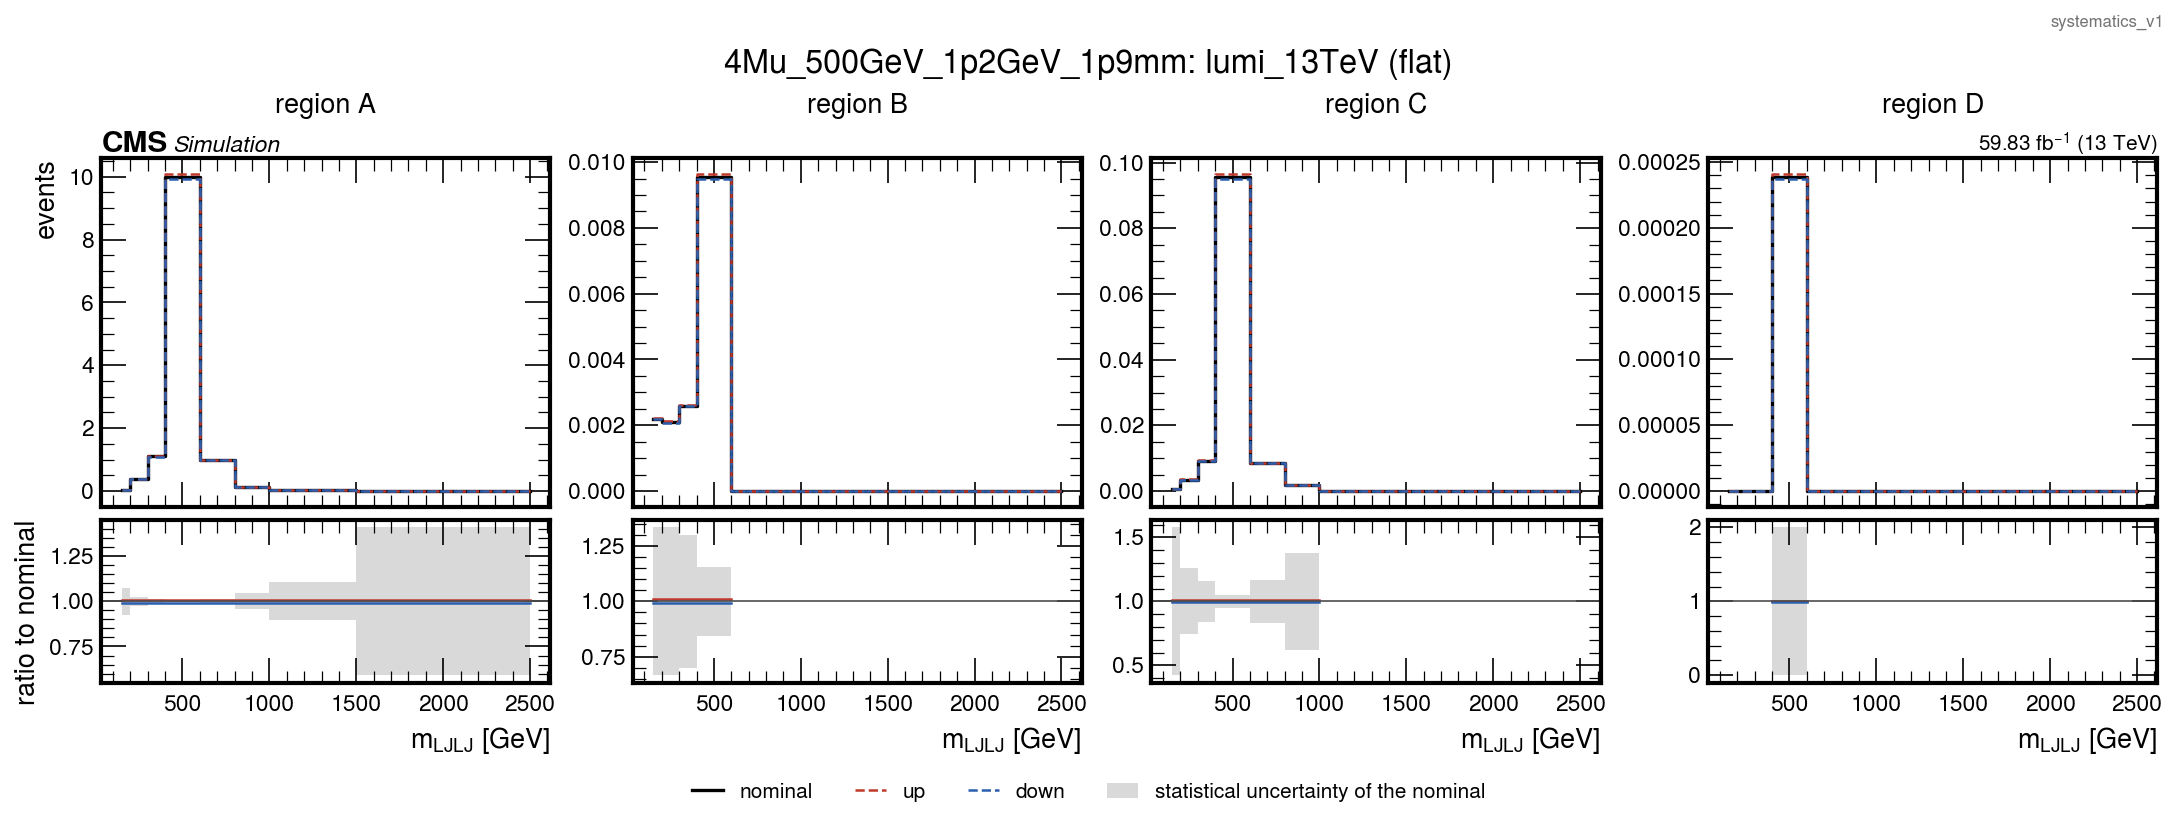

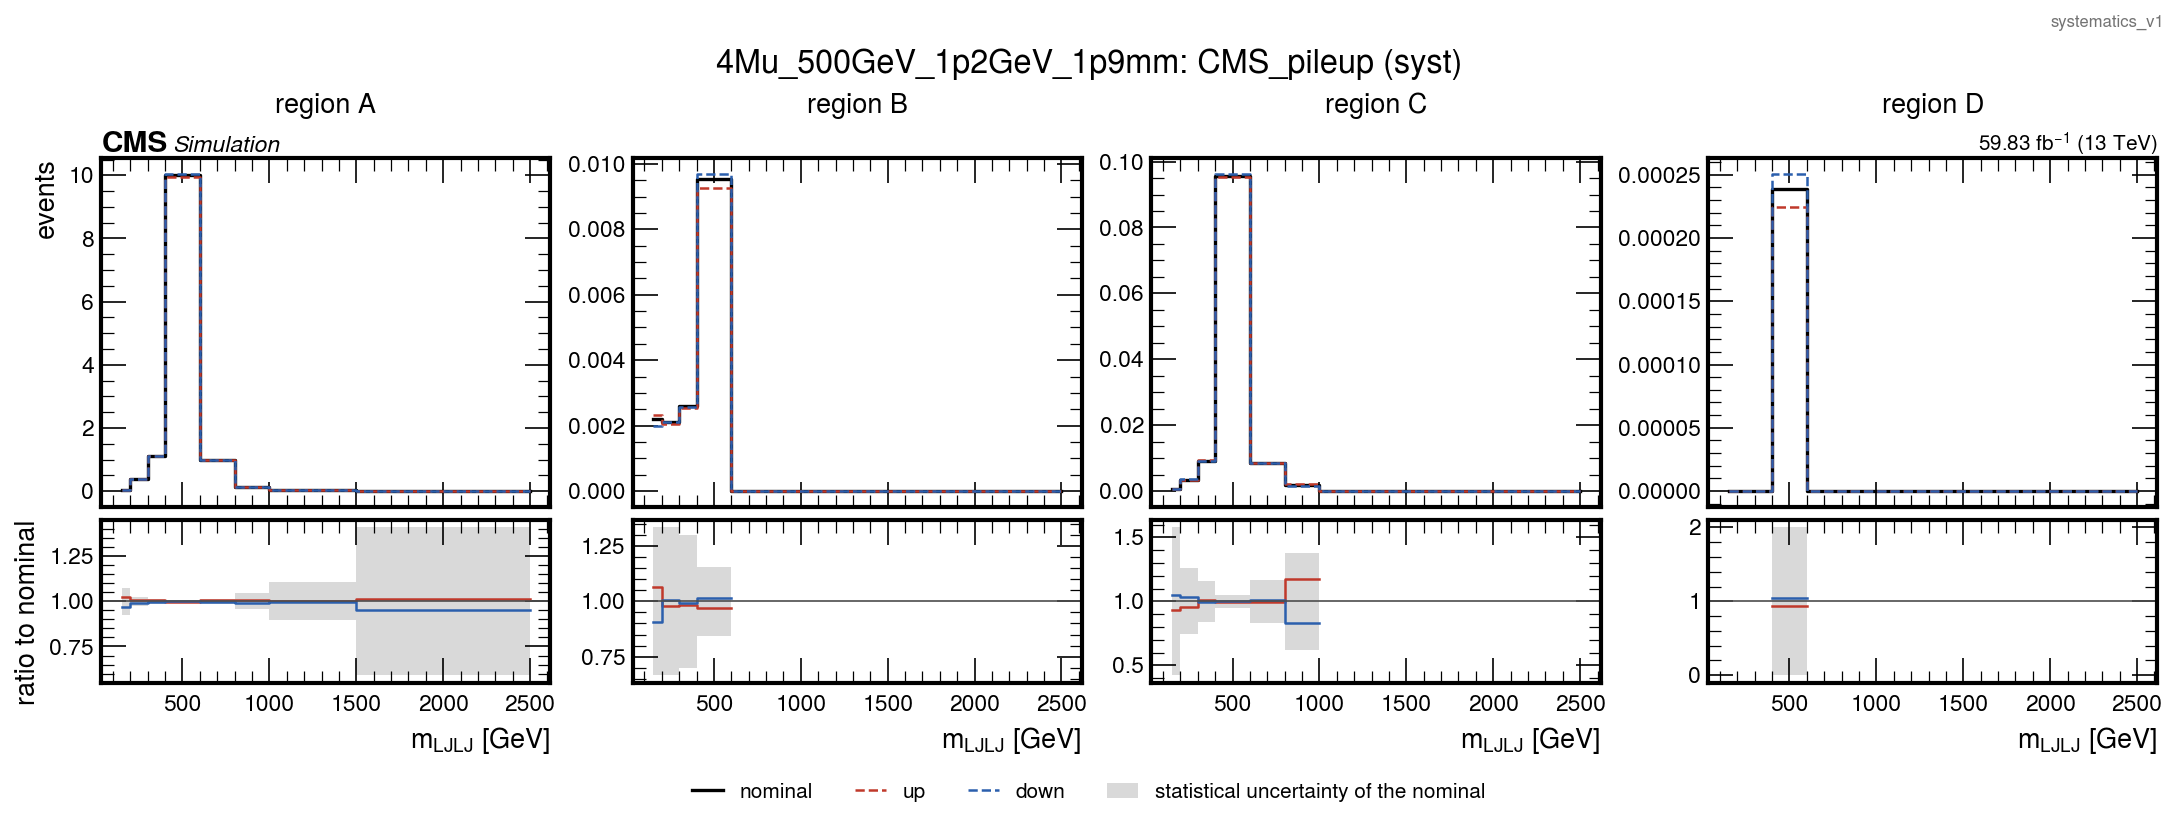

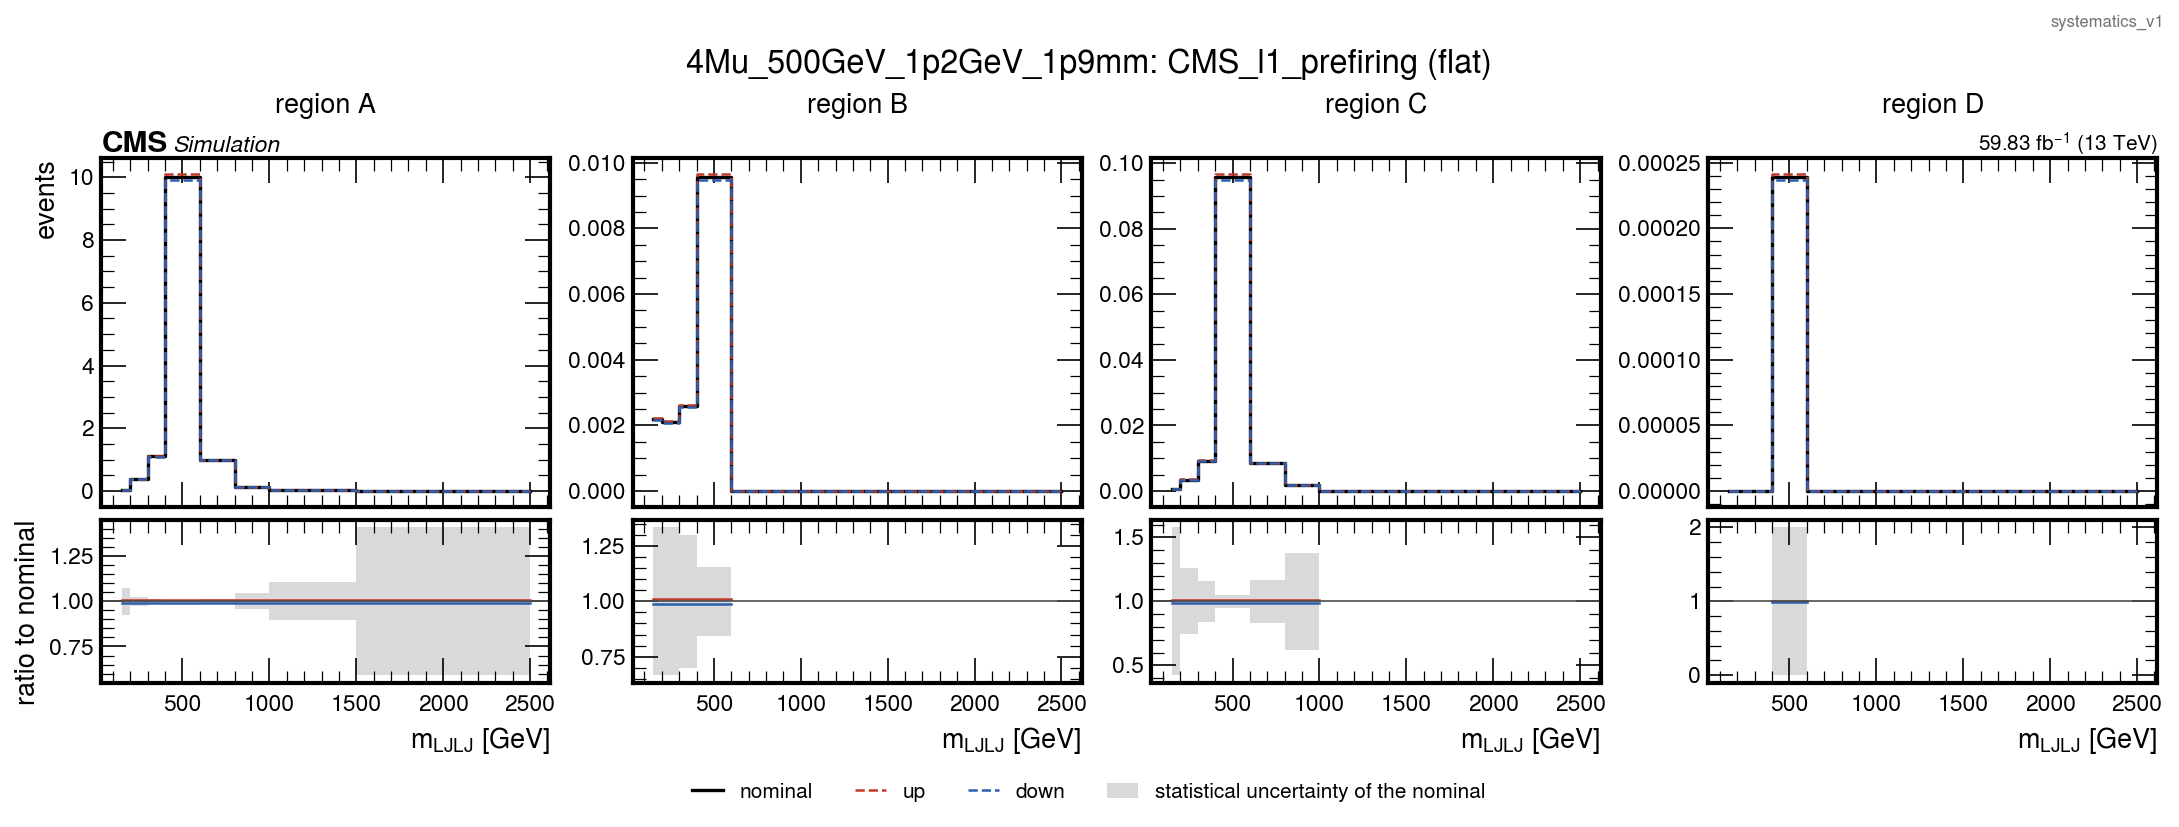

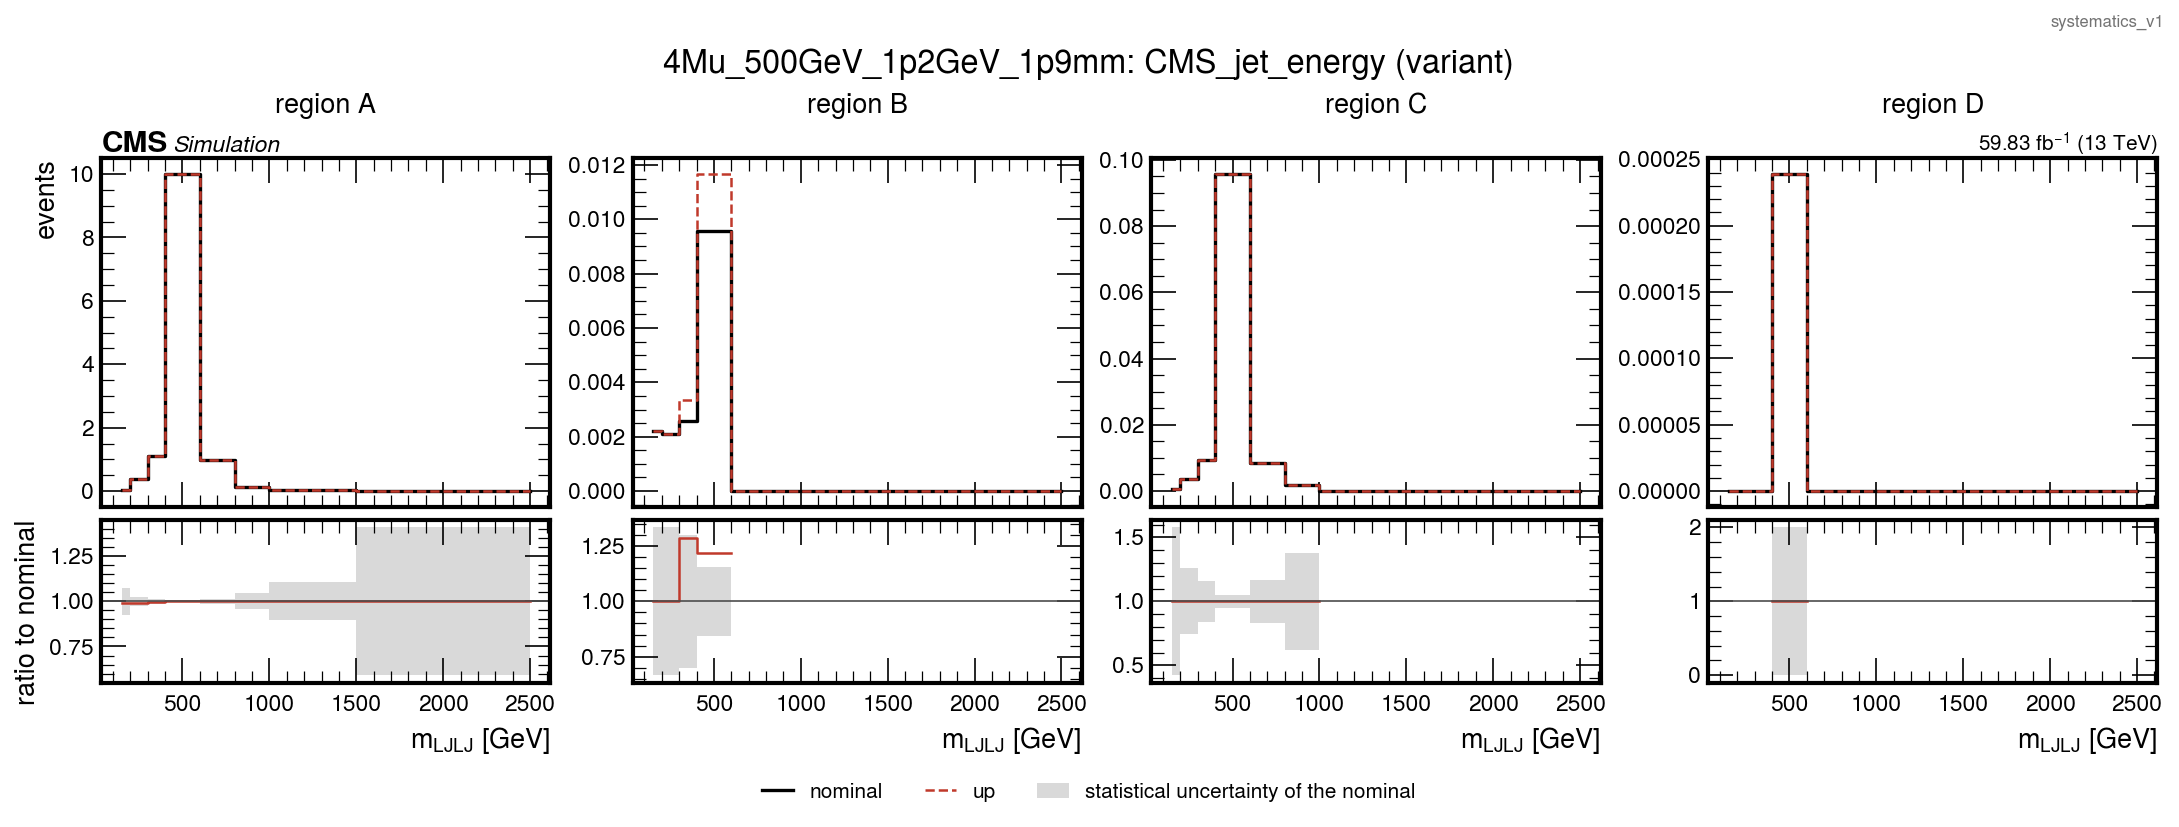

In [2]:
for channel, point in POINTS.items():
    out = dt.read_coffea(f"{INPUT_DIR}/{point}.coffea")[point]
    nominal = sysstudy.st.region_shapes_6d(out, channel, sysstudy.PLANE, point,
                                           selection=sysstudy.WORKING_POINTS[channel])
    for nuisance, entry in REGISTRY.items():
        varied = sysstudy.variations(out, point, channel, entry, nominal)
        show(pt.variation_plot(nominal, varied, FIGURES, CAMPAIGN, f"templates_{nuisance}_{point}",
                               title=f"{point}: {nuisance} ({next(iter(entry))})"))

**Interpretation (run of 2026-11-14: `systematics_v1`, four systematics).**
Both points put their signal in the 400 to 600 GeV bin of region A, with a few percent or less in
B, C and D.

* Luminosity and prefiring scale every bin by the same factor, by construction.
* Pileup changes region A by less than 1% in the populated bins, flat within the statistical
  band; its larger excursions are in bins and regions that hold almost no signal.
* The jet energy variation moves signal from region A to region B, as a few lepton jets cross the
  isolation cut: region A loses about 0.5% (2Mu2E) and 0.1% (4Mu), and the small yield in B
  grows by 20 to 25%. Within region A the change is flat.

**For the analysis:** all four act on the normalisation of each region, which is what one
log-normal value per region in the cards describes; none needs a shape uncertainty in
$m_{LJLJ}$. The migration from A to B is carried by the region-dependent values of
`CMS_jet_energy`.

## 2. Size across the signal grid

In region A, at every point of the limit grid: the size of each systematic that varies from
point to point (half the difference of up and down for an asymmetric one), and the
statistical uncertainty of the simulated signal, which the cards carry as the `mcstat`
rows. A flat entry has the same size everywhere and is only listed.

lumi_13TeV: 0.83% at every point
CMS_l1_prefiring: 1.00% at every point


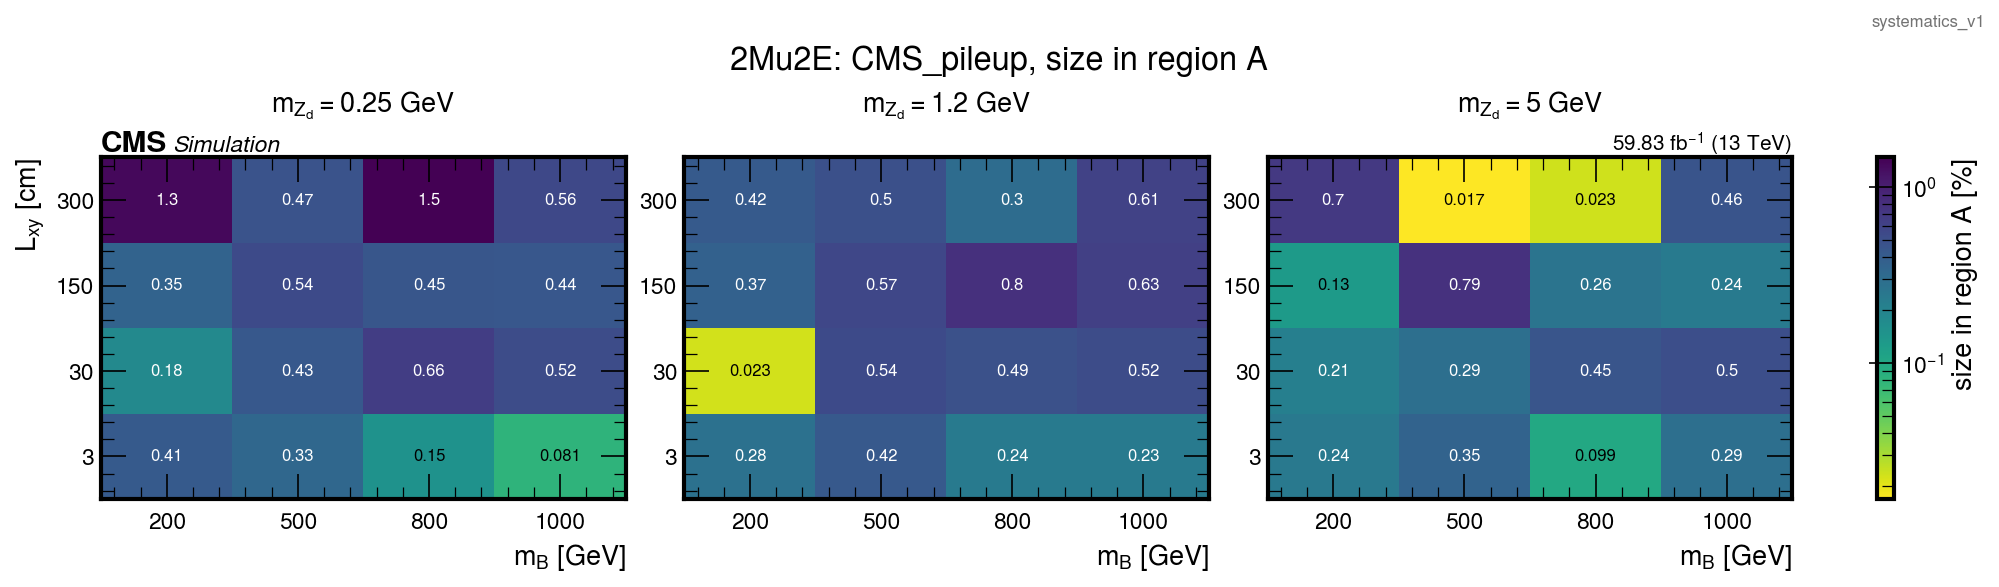

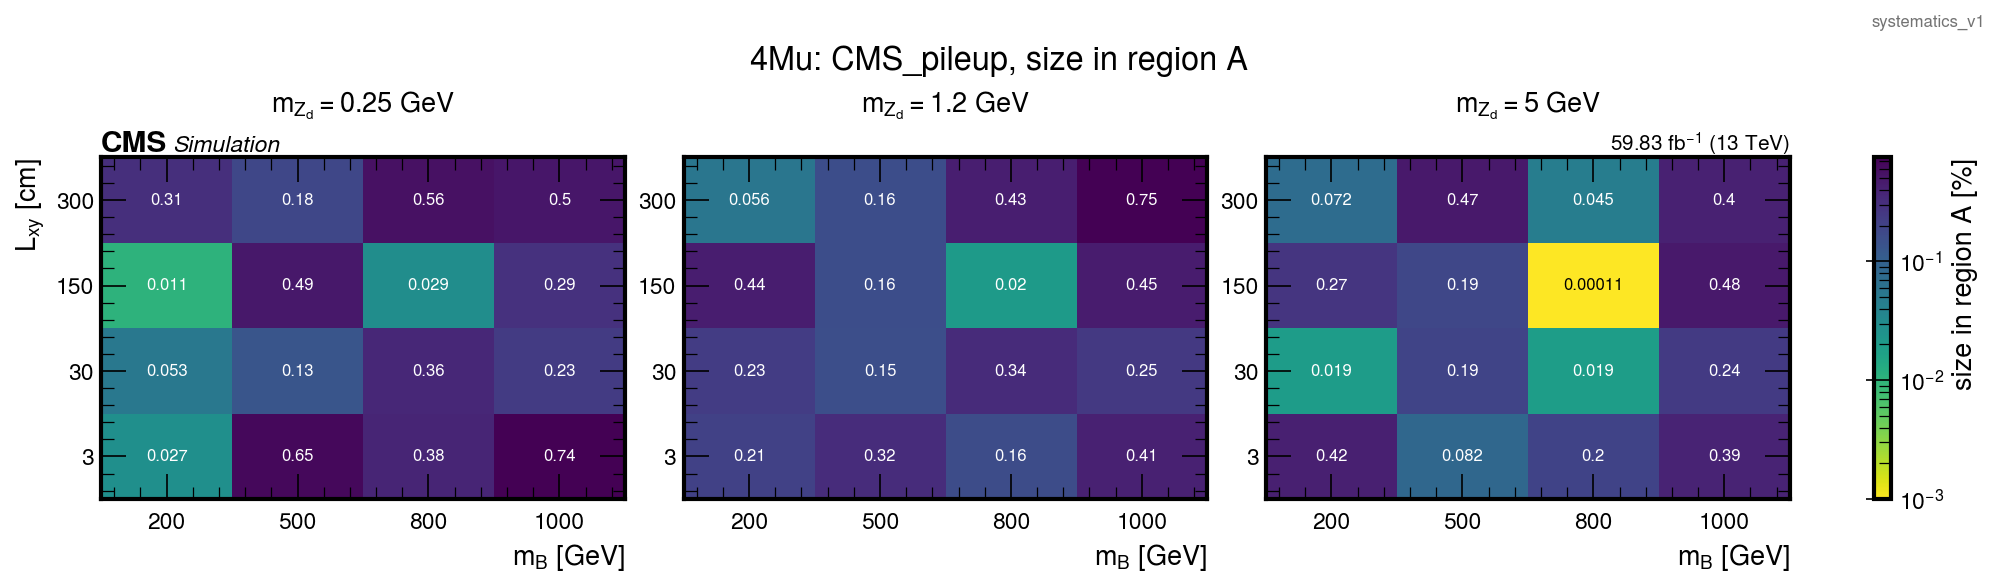

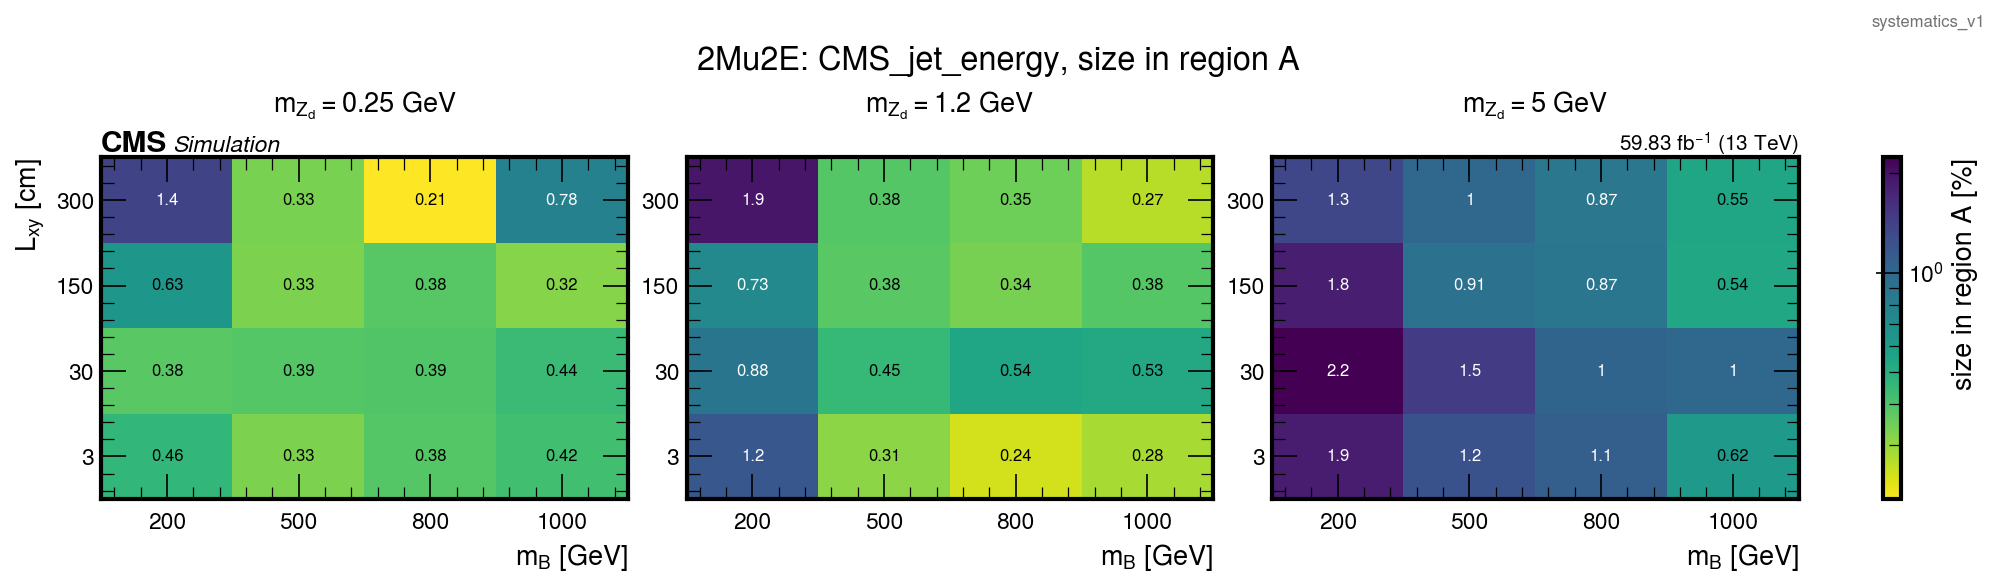

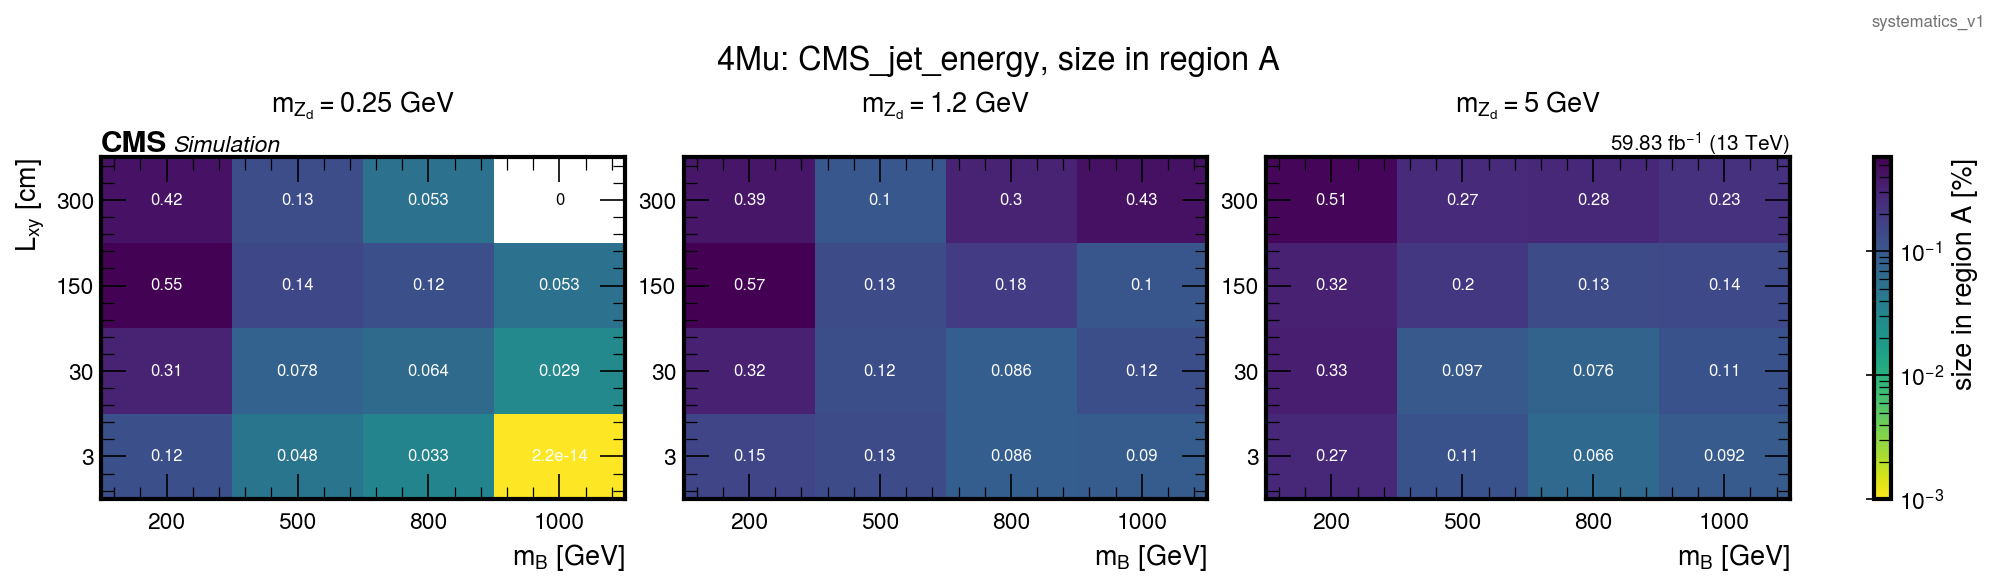

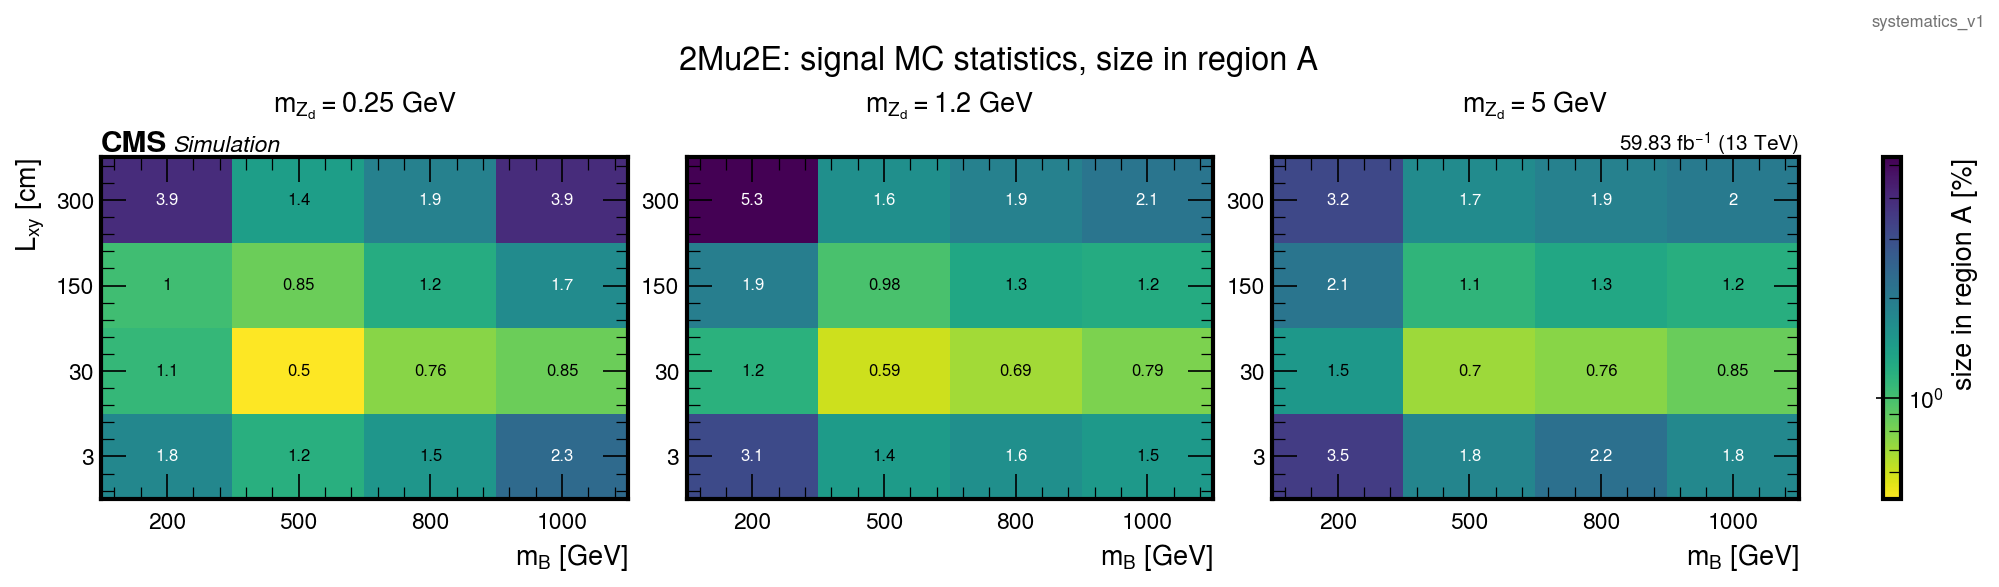

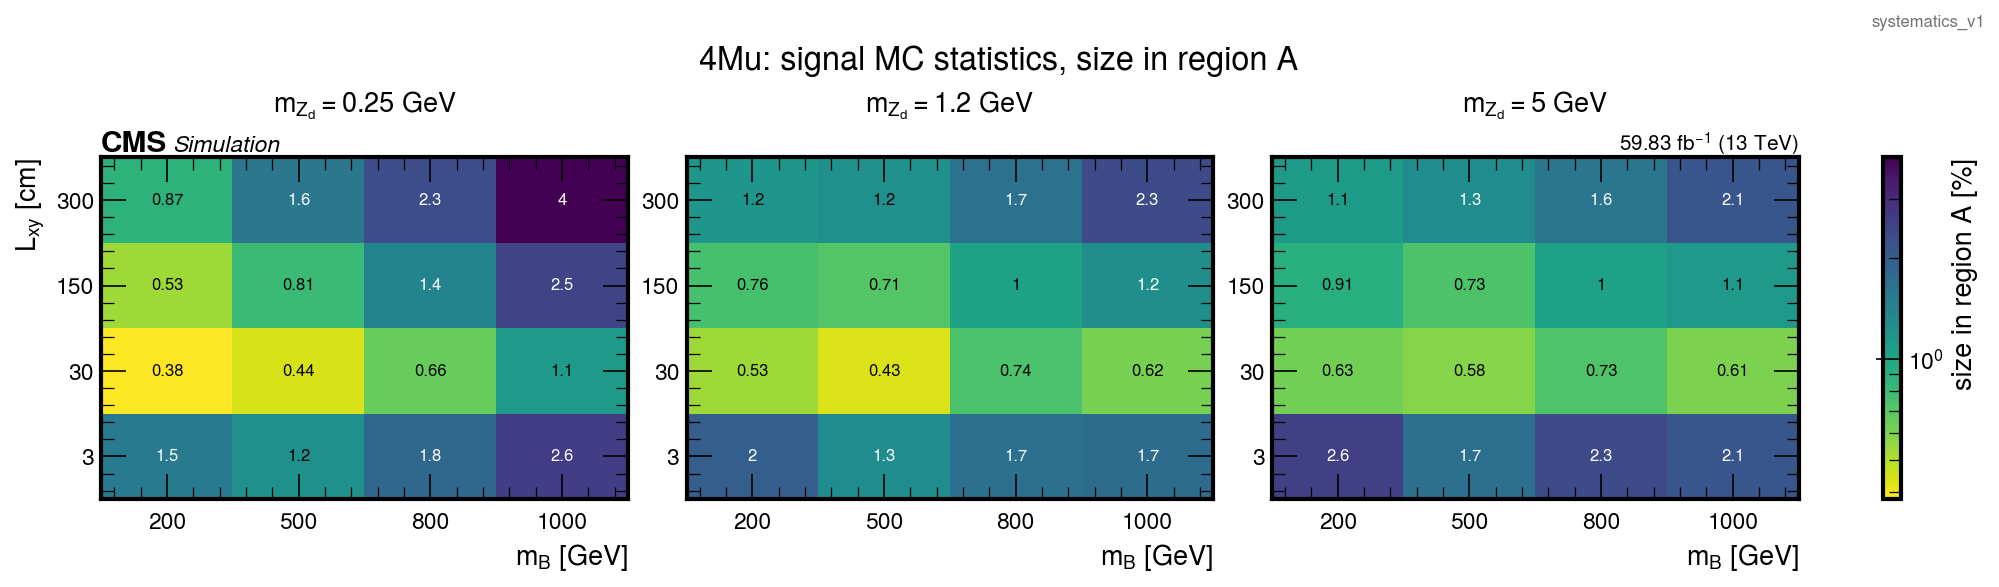

In [3]:
maps = {}
for nuisance, entry in REGISTRY.items():
    if "flat" in entry:
        print(f"{nuisance}: {100 * entry['flat']:.2f}% at every point")
    else:
        maps[nuisance] = {s: 100 * sysstudy.kappa_size(KAPPAS[s][nuisance]["A"]) for s in LIMIT}

payloads = {}
for channel in POINTS:
    with fsspec.open(f"{LIMITS_DIR}/inputs/with/shapes_{channel}.json") as f:
        payloads[channel] = json.load(f)
channel_of = {s: sysstudy.FINAL_STATE_CHANNEL[s.split("_")[0]] for s in LIMIT}
maps["signal MC statistics"] = {s: 100 * sysstudy.signal_mc_stat(payloads[channel_of[s]], s, channel_of[s])
                                for s in LIMIT}

for label, sizes in maps.items():
    rows = [dict(pt.parse_point(s), signal=s, size=v) for s, v in sizes.items()]
    for final_state in ("2Mu2E", "4Mu"):
        show(pt.exclusion_map(rows, final_state, FIGURES, CAMPAIGN, name=f"size_{label.replace(' ', '_')}_{final_state}",
                              field="size", label="size in region A [%]", outline_below=None,
                              title=f"{final_state}: {label}, size in region A"))

**Interpretation.**
* Pileup shows no trend over the grid: 0.02 to 1.5% for 2Mu2E (at most 0.75% for 4Mu), the
  largest values at $L_{xy}$ = 300 cm, where the simulated signal is scarcest. Notebook 01 found
  most of these within twice their statistical precision, so the pattern from point to point is
  largely statistical.
* The jet energy has a trend: it grows towards heavy dark photons and light bound states, up to
  2.2% at $m_{Z_d}$ = 5 GeV and $m_B$ = 200 GeV (at most 0.57% for 4Mu). Its size is the fraction
  of the signal that a 10% change of the isolation moves across the cut, so more lepton jets sit
  near the cut there.
* The statistical uncertainty of the simulated signal is 0.4 to 5.3% in region A, smallest at
  30 cm and largest at 3 and 300 cm, where fewer simulated events pass. At many points it is the
  largest uncertainty on the signal.

**For the analysis:** a single pileup value (the flat 1.5% fallback covers every point) would be
a fair simplification, while the jet energy is worth keeping per point. More simulated signal
at the shortest and longest lifetimes would reduce the largest signal uncertainty there.

## 3. Impacts

The left panel is the pull of each nuisance, its fitted value against its pre-fit one in
units of the pre-fit uncertainty, with its post-fit uncertainty as the error bar: zero and
one on the Asimov dataset, as in the pull plot of 03_limits. The right panel is the impact:
the shift of the fitted $r$, relative to the fitted value, when the nuisance is fixed one
post-fit standard deviation above (red) or below (blue) its best fit, the largest at the
top. The free background parameters of the ABCD model are left out.

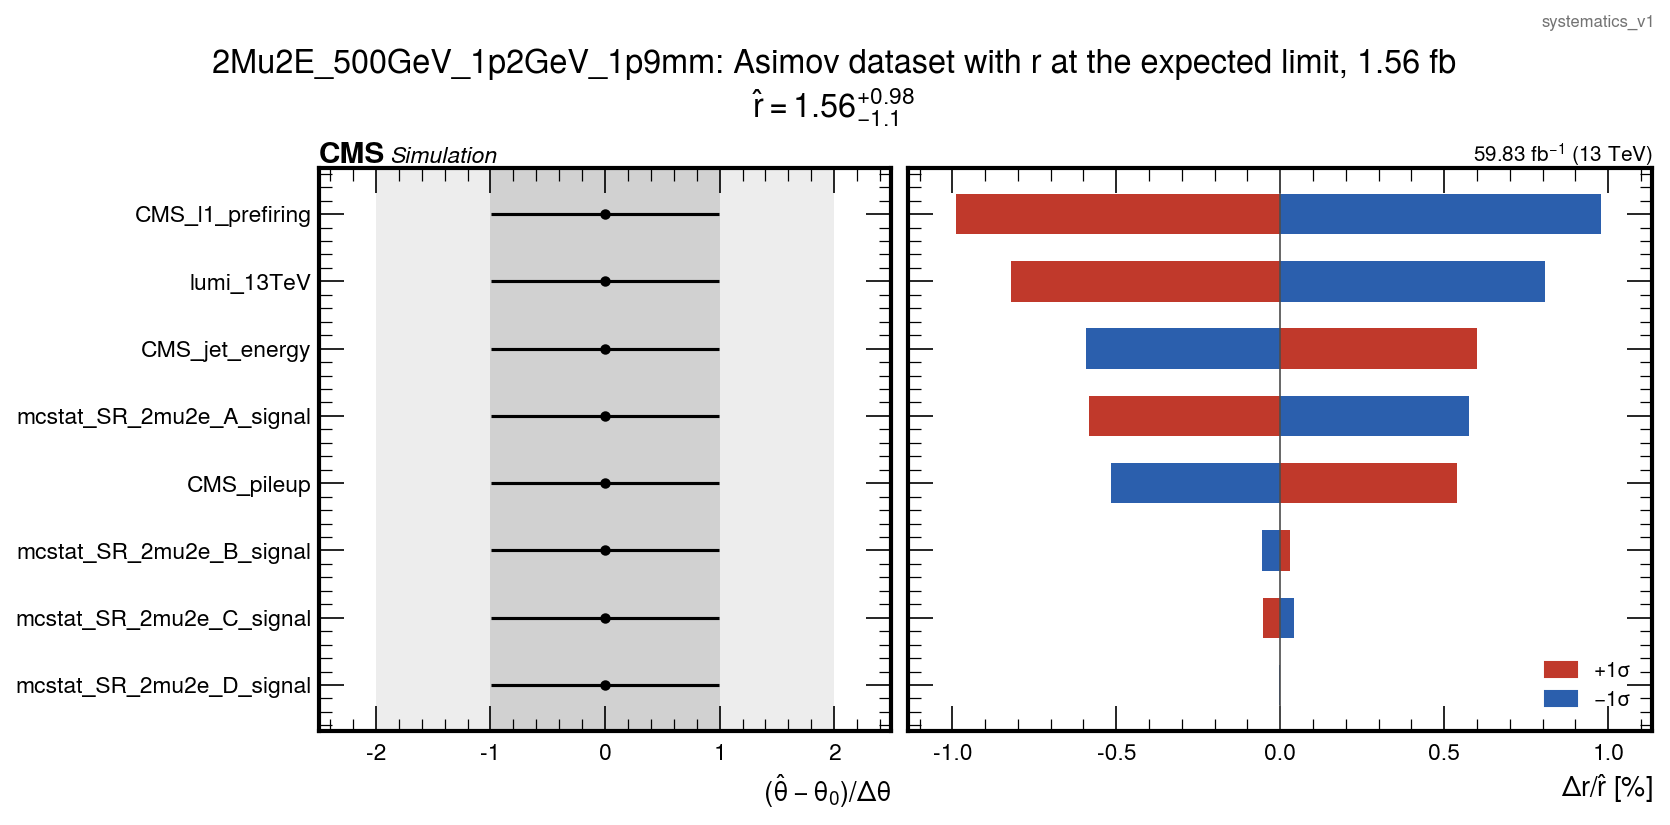

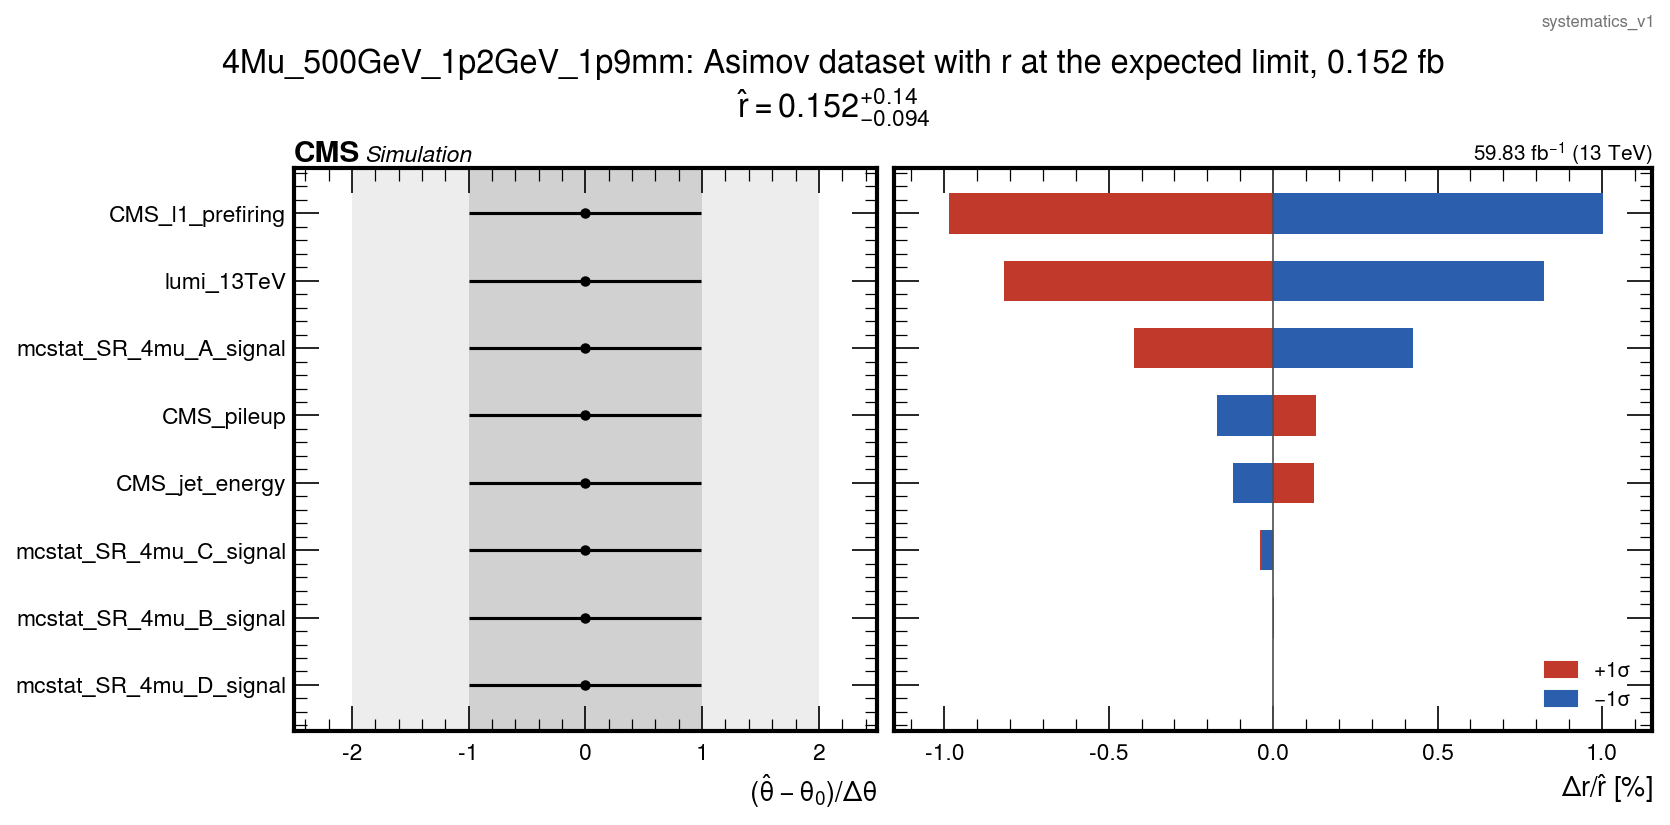

In [4]:
if COMBINE is None:
    raise RuntimeError("Combine is not available here: put `combine` on the PATH or set COMBINE_CMSSW_BASE.")
CARDS = WORK / "cards"
sysstudy.download(f"{LIMITS_DIR}/cards_with", CARDS)   # the cards with corrections and systematics

for channel, point in POINTS.items():
    outdir = WORK / f"impacts_{point}"
    sysstudy.run_script("run_combine_impacts.py", CARDS / f"datacard_shape_{channel}_{point}.txt",
                        "--outdir", outdir, "--expect-signal", f"{EXPECTED[point]:.6g}", "-j", "8",
                        combine=COMBINE, log=WORK / f"impacts_{point}.log")
    impacts = json.loads((outdir / "impacts.json").read_text())
    show(pt.impact_plot(impacts, FIGURES, CAMPAIGN, f"impacts_{point}",
                        title=f"{point}: Asimov dataset with r at the expected limit, {EXPECTED[point]:.3g} fb"))

**Interpretation.** With the signal at the expected limit, each nuisance moves $\hat r$ by about
its own size: prefiring 1%, luminosity 0.8%, the statistical uncertainty of the signal in region
A 0.6% (2Mu2E) and 0.4% (4Mu), pileup and jet energy 0.1 to 0.6%. The signal statistics of B, C
and D move nothing, because hardly any signal is there. A signal normalisation uncertainty is
equivalent to a change of $r$, hence the one-to-one impacts, and the pulls stay at zero with
full-size error bars, as in the pull plot of 03_limits. All impacts are at the 1% level, against
a statistical uncertainty of $r$ of 60 to 90% at the expected limit.

**For the analysis:** on the fitted signal strength the systematics are negligible next to the
statistics. The largest is prefiring, a flat 1% whose DSA-muon part is an estimate; computing the
prefiring of DSA muons (open item 5 of the README) would make it smaller and per point.

## 4. Limit breakdown

The expected limits of the limit grid, computed as in 03_limits (to a relative precision of
$10^{-4}$) with nuisances fixed at their nominal values, which is the same as leaving them
out of the cards: each systematic in turn, all of them, and every constrained nuisance
("statistics only", which also fixes the statistical uncertainty of the simulated signal).
Each dot is one signal point: how much higher, in percent, the limit with every systematic
is than the limit without the nuisances of that column. The bar is the median.

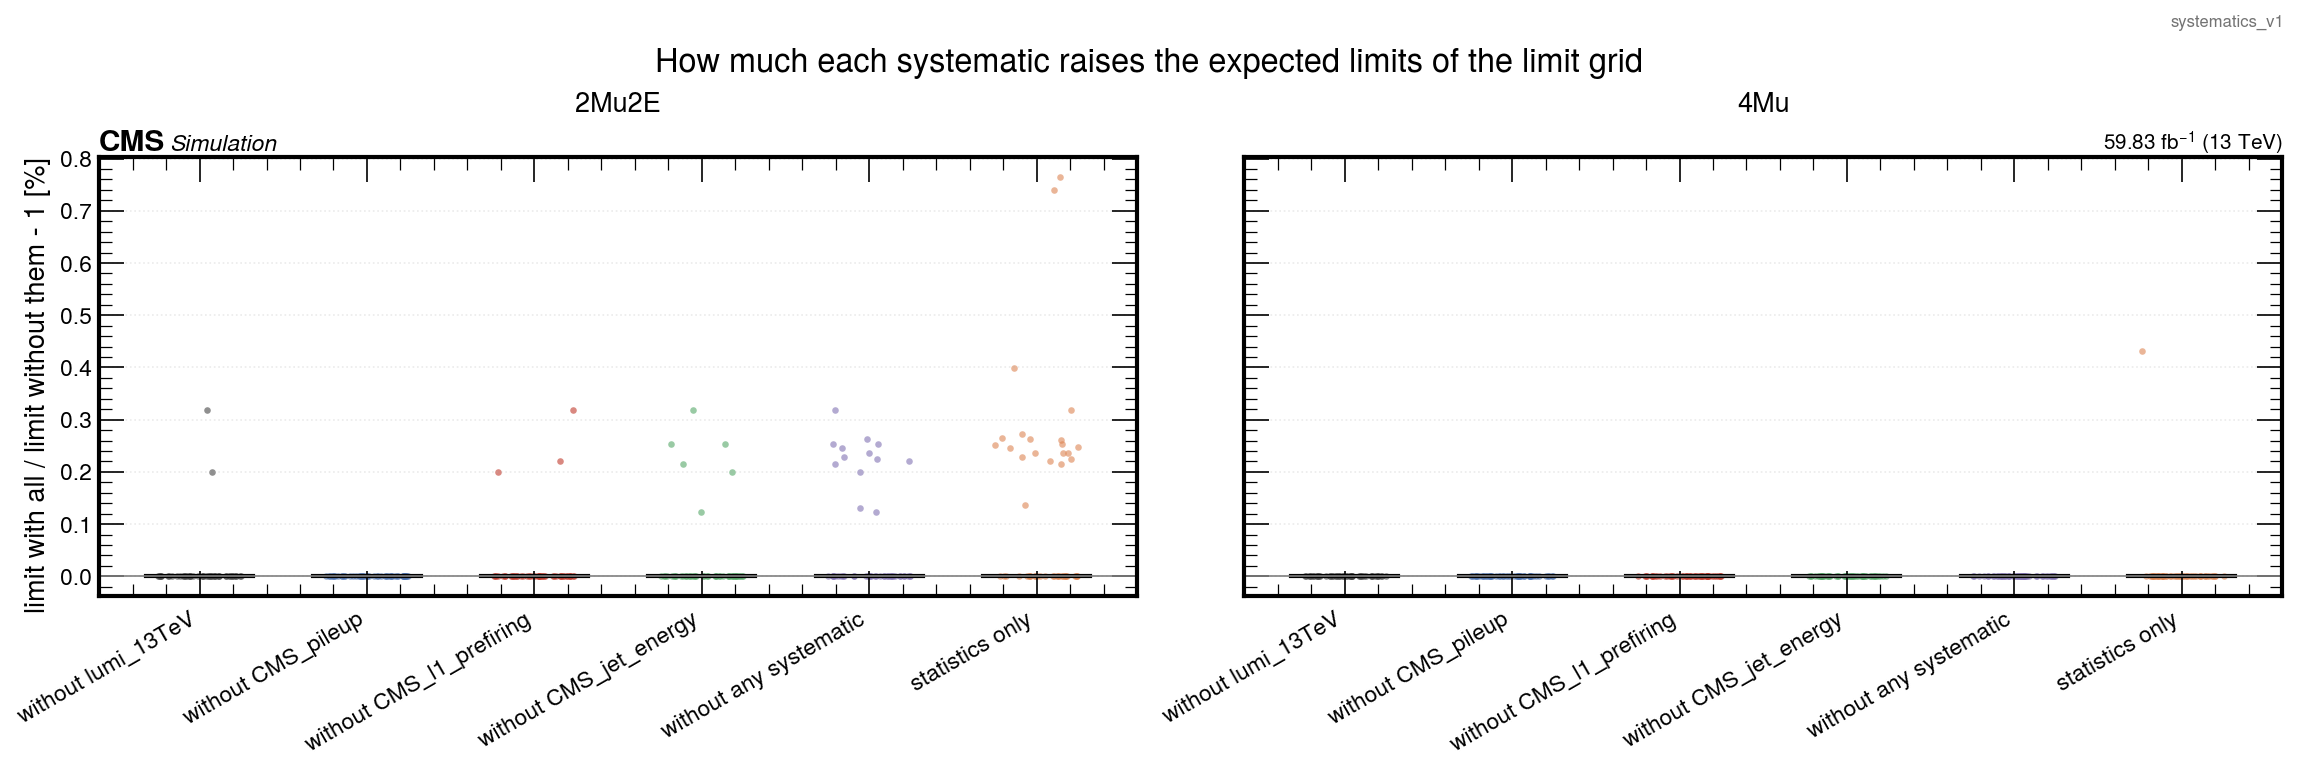

                              2Mu2E: median, max (%)        4Mu: median, max (%)
without lumi_13TeV                  0.000      0.318            0.000      0.000
without CMS_pileup                  0.000      0.000            0.000      0.000
without CMS_l1_prefiring            0.000      0.318            0.000      0.000
without CMS_jet_energy              0.000      0.318            0.000      0.000
without any systematic              0.000      0.318            0.000      0.000
statistics only                     0.000      0.765            0.000      0.432


In [5]:
grid = WORK / "cards_grid"   # the cards of the limit grid, next to their workspaces
grid.mkdir()
for s in LIMIT:
    name = f"datacard_shape_{channel_of[s]}_{s}.txt"
    (grid / name).symlink_to(CARDS / name)
for workspace in CARDS.glob("param_ws_*.root"):
    (grid / workspace.name).symlink_to(workspace)

variants = sysstudy.freeze_variants(REGISTRY)
limits = {}
for label, frozen in variants.items():
    tag = label.replace(" ", "_")
    sysstudy.run_script("run_combine_limits.py", "--datacards", grid, "--pattern", "datacard_shape_*.txt",
                        "--outdir", WORK / f"limits_{tag}", "-j", "8",
                        f"--extra=--rRelAcc 0.0001 --rAbsAcc 0.00001 --freezeParameters {frozen}",
                        combine=COMBINE, log=WORK / f"limits_{tag}.log", check=False)
    limits[label] = {r["signal"]: r["exp"] for r in pt.as_rows(WORK / f"limits_{tag}" / "limits.csv")}

changes = {final_state: {label: [100 * (EXPECTED[s] / limits[label][s] - 1) for s in sorted(LIMIT)
                                 if s.startswith(final_state + "_") and s in limits[label]]
                         for label in variants}
           for final_state in ("2Mu2E", "4Mu")}
show(pt.breakdown_plot(changes, FIGURES, CAMPAIGN, "limit_breakdown",
                       title="How much each systematic raises the expected limits of the limit grid",
                       ylabel="limit with all / limit without them - 1 [%]"))

print(f"{'':24s}" + "".join(f"{fs + ': median, max (%)':>28s}" for fs in changes))
for label in variants:
    print(f"{label:24s}" + "".join(f"{np.median(changes[fs][label]):17.3f} {max(changes[fs][label]):10.3f}"
                                   for fs in changes))

**Interpretation.** The systematics do not change the expected limits. Leaving out any one of
them leaves the limit unchanged, to the four decimals Combine prints, at all but at most six of
the 96 points (none for pileup); leaving out all four changes 13 points by 0.1 to 0.3%, and
fixing every constrained nuisance (statistics only) changes 21 points by at most 0.8%. A
signal-only uncertainty of about 1% enters an expected limit only at second order, about 0.01%
here, below that precision. The points that move, move by the same amount whichever systematic
is removed (for example 2Mu2E_800GeV_1p2GeV_1p2mm, from 0.7573 to 0.7549 fb without luminosity,
prefiring or jet energy, and not at all without pileup), so they are small jumps of the limit
calculation at those points, not effects of the systematics.

**For the analysis:** the expected sensitivity is set by the statistics of the background
estimate, not by these systematics. The plot will show structure once larger uncertainties
enter, such as the lepton-jet reconstruction efficiency or a background shape uncertainty.

Everything but the copies of the cards goes to EOS, and the local working directory is removed.

In [6]:
for copies in WORK.glob("cards*"):
    shutil.rmtree(copies)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1_limits/effects
